In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

In [2]:
# get matched subreddits
input_fpath = f"{DATAPATH}/data/samples"
X0 = 10; N0 = 1
X1 = 20; N1 = 10
X2 = "inf"; N2 = 1
covs1 = "lifetime_d"
covs2 = "lifetime_d_n_post_author_till2019_log"
matched1_indp_df = pd.read_csv(f"{input_fpath}/cem-batch4-new/matched_table_banned_3274_cem_X{X0}N{N0}_{covs1}.csv")
matched2_indp_df = pd.read_csv(f"{input_fpath}/cem-batch4-new/matched_table_banned_3274_cem_X{X1}N{N1}_{covs2}.csv")
matched2_conn_df = pd.read_csv(f"{input_fpath}/cem-batch4-new/matched_table_banned_3274_cem_X{X2}N{N2}_{covs2}.csv")

# get banned subreddits and random samples
samples_df = pd.read_csv(f"{DATAPATH}/data/samples/to_match_table_selfid_banned_3274_260528.csv")
samples_df = samples_df[samples_df["lifetime_d"]>0]

banned_df = samples_df[samples_df["if_banned"]==1]
random_df = samples_df[samples_df["if_banned"]==0].sample(n=len(banned_df), replace=False, random_state=42)

# banned_random_df = pd.concat([banned_df, random_df])
# banned_random_df.to_csv(f"{DATAPATH}/data/samples/sample_banned_random_3274_250629.csv", index=False)

matched1_indp = set(matched1_indp_df[matched1_indp_df["if_banned"]==0]["subreddit"].tolist())
matched2_indp = set(matched2_indp_df[matched2_indp_df["if_banned"]==0]["subreddit"].tolist())
matched2_conn = set(matched2_conn_df[matched2_conn_df["if_banned"]==0]["subreddit"].tolist())
random = set(random_df["subreddit"].tolist())
banned = set(banned_df["subreddit"].tolist())
print(len(matched1_indp), len(matched2_indp), len(matched2_conn), len(random), len(banned))

3274 3274 3274 3274 3274


In [5]:
input_dir = f"{DATAPATH}/output/toxicity/subset3274/detoxify-multilingual-all-subm-perweek/"

results_banned = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-by-subm-toxicity.parquet")
results_matched1_indp = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs1}-X{X0}N{N0}-by-subm-toxicity.parquet")
results_matched2_indp = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X1}N{N1}-by-subm-toxicity.parquet")
results_matched2_conn = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X2}N{N2}-by-subm-toxicity.parquet")
results_random = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-random-by-subm-toxicity.parquet")
detoxify_results_dict = {
    "banned": results_banned,
    "matched1_indp": results_matched1_indp,
    "matched2_indp": results_matched2_indp,
    "matched2_conn": results_matched2_conn,
    "random": results_random
}

detoxify_results = pl.concat(
    [df.with_columns(pl.lit(label).alias("group"))
     for label, df in detoxify_results_dict.items()], 
     how="vertical",
)
detoxify_results

id,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,group
str,f64,f64,f64,f64,f64,f64,str
"""100315""",0.092224,0.000037,0.000634,0.000536,0.054291,0.000376,"""banned"""
"""1003oj""",0.000287,0.000093,0.000629,0.000079,0.000634,0.000222,"""banned"""
"""1003tf""",0.000724,0.000057,0.000462,0.000112,0.000443,0.000163,"""banned"""
"""1006nn""",0.079468,0.000166,0.003376,0.005081,0.005959,0.000379,"""banned"""
"""1007le""",0.267334,0.001255,0.046295,0.001755,0.016098,0.0047,"""banned"""
…,…,…,…,…,…,…,…
"""zzzrk""",0.684082,0.002415,0.445068,0.000907,0.057587,0.00279,"""random"""
"""zzzuv""",0.000511,0.000028,0.000234,0.000033,0.000225,0.000082,"""random"""
"""zzzwu""",0.44751,0.00172,0.20105,0.000947,0.047241,0.00109,"""random"""


In [11]:
openai_results = pl.read_parquet("/cinddata/reddit-ban-study/output/toxicity/openai-eval/omni-moderation-latest/subm-comm-from-subr-5groups-random-5000-toxicity.parquet")
openai_results

id,flagged,harassment,harassment_threatening,hate,hate_threatening,self_harm,self_harm_instructions,self_harm_intent,sexual,sexual_minors,violence,violence_graphic,illicit,illicit_violent
str,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""1073kz""",false,0.000084,0.000004,0.00125,0.000003,0.000002,2.2603e-7,7.6465e-7,0.000018,0.000001,0.000005,0.000002,0.000013,0.000006
"""10c68m""",false,0.00496,0.000002,0.000005,6.6815e-8,0.000008,3.1876e-7,0.000003,0.000004,2.0580e-7,0.000004,0.000001,0.000003,0.000002
"""10gcdc""",false,0.00081,0.000765,0.001236,0.000008,0.000453,0.000002,0.000005,0.000014,0.000001,0.000493,0.000004,0.020299,0.000057
"""10hhi7""",false,0.00054,0.000005,0.000028,2.4061e-7,0.000005,8.9397e-7,0.000001,0.002722,0.000004,0.000018,0.000013,0.000005,0.000003
"""10jr3w""",false,0.000028,0.000004,0.000023,3.5009e-7,0.000005,7.6465e-7,0.000004,0.000008,4.9370e-7,0.000008,0.000001,0.000012,0.000003
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""zry3v""",false,0.000071,0.000007,0.000022,0.000002,0.000012,0.000003,0.000006,0.000083,0.000005,0.000551,0.000014,0.00002,0.000027
"""zx1bk""",true,0.522931,0.334271,0.086681,0.005099,0.004727,0.000229,0.000302,0.000097,0.000017,0.942723,0.016046,0.062677,0.044265
"""zxa7d""",false,0.000042,0.000005,0.000015,4.6379e-7,0.000005,0.000001,0.000002,0.000859,0.00002,0.000529,0.000013,0.000013,0.000008


In [12]:
detoxify_cols = [
    "toxicity", "severe_toxicity", "obscene",
    "threat", "insult", "identity_attack",
]

openai_cols = [c for c, dtype in openai_results.schema.items() if dtype.is_float()]
print("OpenAI score columns:", openai_cols)

OpenAI score columns: ['harassment', 'harassment_threatening', 'hate', 'hate_threatening', 'self_harm', 'self_harm_instructions', 'self_harm_intent', 'sexual', 'sexual_minors', 'violence', 'violence_graphic', 'illicit', 'illicit_violent']


In [32]:
detoxify_scores = (
    detoxify_results
    .rename({c: f"{c}_detoxify" for c in detoxify_cols})
    .unique(subset=["id"], keep="first")
)

merged = (
    openai_results
    .rename({c: f"{c}_openai" for c in openai_cols})
    .join(
        detoxify_scores,
        on="id",
        how="left",
        validate="m:1",
    )
)

merged

id,flagged,harassment_openai,harassment_threatening_openai,hate_openai,hate_threatening_openai,self_harm_openai,self_harm_instructions_openai,self_harm_intent_openai,sexual_openai,sexual_minors_openai,violence_openai,violence_graphic_openai,illicit_openai,illicit_violent_openai,toxicity_detoxify,severe_toxicity_detoxify,obscene_detoxify,threat_detoxify,insult_detoxify,identity_attack_detoxify,group
str,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""1073kz""",false,0.000084,0.000004,0.00125,0.000003,0.000002,2.2603e-7,7.6465e-7,0.000018,0.000001,0.000005,0.000002,0.000013,0.000006,0.000741,0.004417,0.029984,0.001734,0.024139,0.005241,"""matched2_conn"""
"""10c68m""",false,0.00496,0.000002,0.000005,6.6815e-8,0.000008,3.1876e-7,0.000003,0.000004,2.0580e-7,0.000004,0.000001,0.000003,0.000002,0.007755,0.000066,0.00149,0.000077,0.003944,0.000325,"""random"""
"""10gcdc""",false,0.00081,0.000765,0.001236,0.000008,0.000453,0.000002,0.000005,0.000014,0.000001,0.000493,0.000004,0.020299,0.000057,0.000764,0.001661,0.013901,0.001037,0.010368,0.002684,"""matched2_conn"""
"""10hhi7""",false,0.00054,0.000005,0.000028,2.4061e-7,0.000005,8.9397e-7,0.000001,0.002722,0.000004,0.000018,0.000013,0.000005,0.000003,0.035828,0.000202,0.000813,0.000926,0.002924,0.031021,"""random"""
"""10jr3w""",false,0.000028,0.000004,0.000023,3.5009e-7,0.000005,7.6465e-7,0.000004,0.000008,4.9370e-7,0.000008,0.000001,0.000012,0.000003,0.013374,0.000431,0.004135,0.000358,0.00589,0.001065,"""random"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""zry3v""",false,0.000071,0.000007,0.000022,0.000002,0.000012,0.000003,0.000006,0.000083,0.000005,0.000551,0.000014,0.00002,0.000027,0.00502,0.000568,0.006744,0.000424,0.00407,0.001748,"""matched2_indp"""
"""zx1bk""",true,0.522931,0.334271,0.086681,0.005099,0.004727,0.000229,0.000302,0.000097,0.000017,0.942723,0.016046,0.062677,0.044265,0.203247,0.00033,0.001285,0.132568,0.004829,0.000544,"""random"""
"""zxa7d""",false,0.000042,0.000005,0.000015,4.6379e-7,0.000005,0.000001,0.000002,0.000859,0.00002,0.000529,0.000013,0.000013,0.000008,0.000215,0.000056,0.000242,0.00006,0.000303,0.000174,"""random"""


In [33]:
# 3. Calculate correlations using posts with all selected scores available
score_cols = (
    [f"{c}_detoxify" for c in detoxify_cols]
    + [f"{c}_openai" for c in openai_cols]
)

scores = (
    merged.select(score_cols)
    .to_pandas()
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

print(f"Rows used for correlation: {len(scores):,}")
corr = scores.corr(method="spearman", min_periods=3)

Rows used for correlation: 24,993


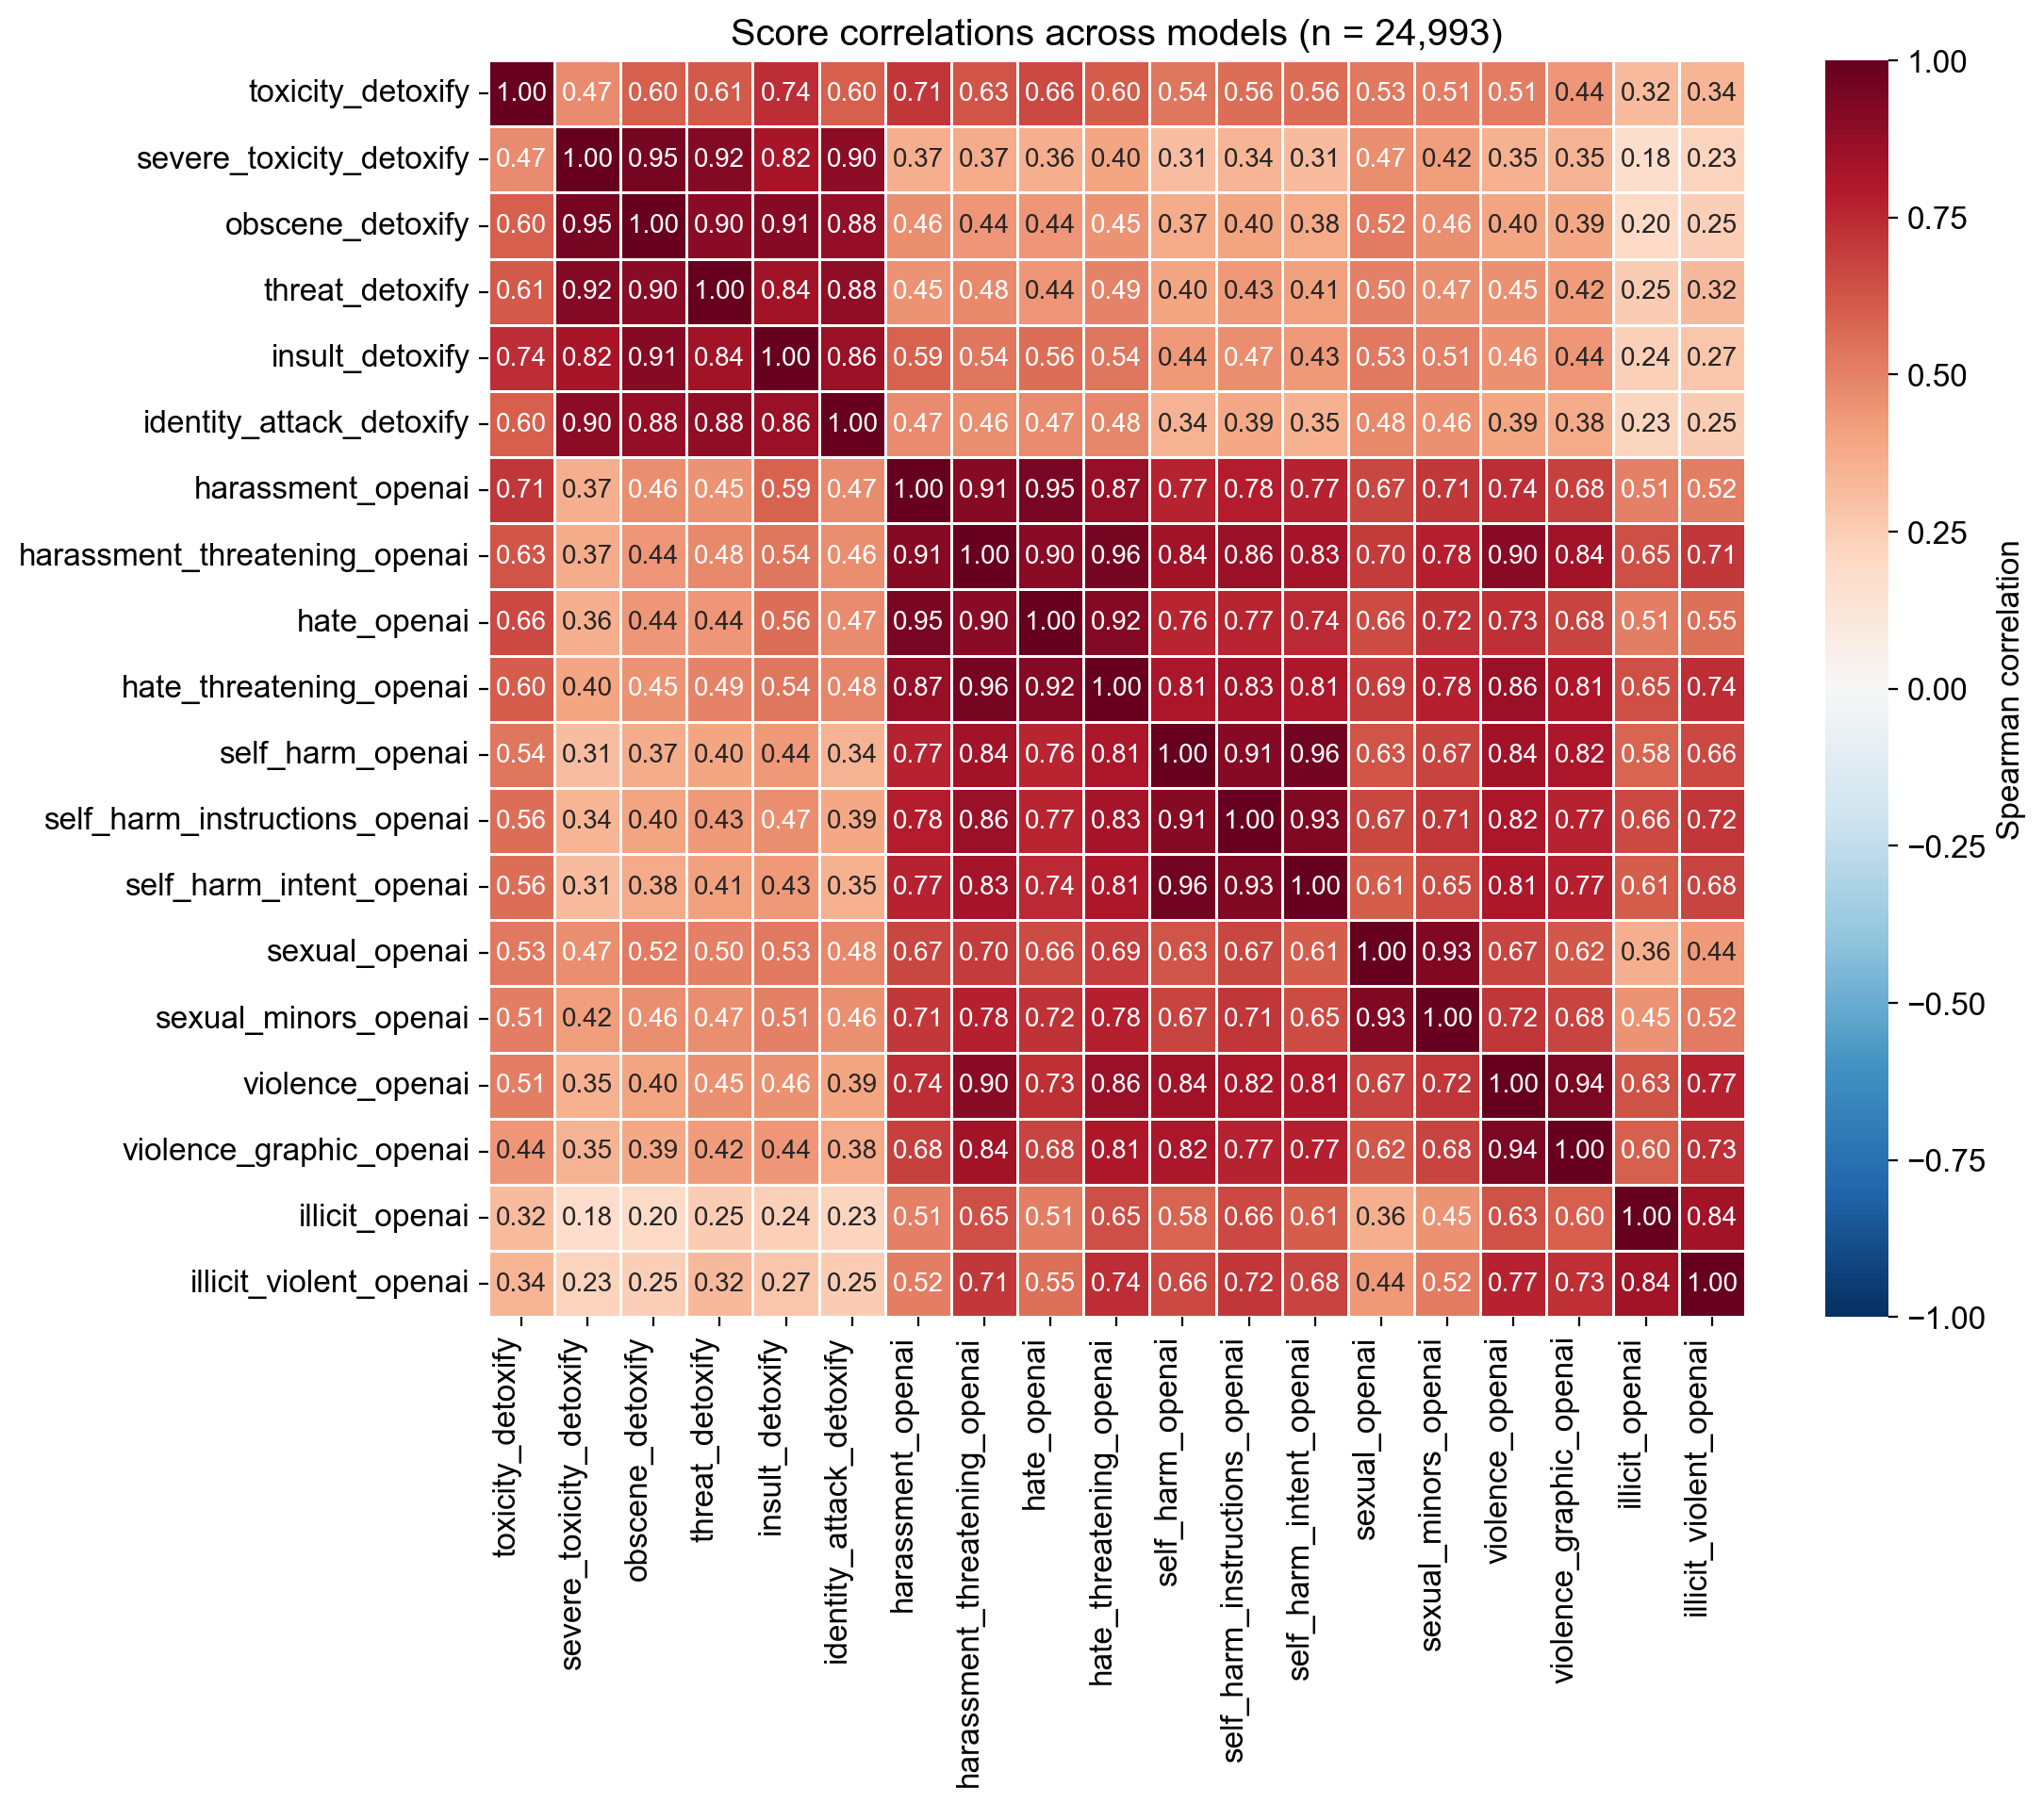

In [39]:

import seaborn as sns

# 4. Visualize the full matrix
fig, ax = plt.subplots(
    figsize=(max(10, len(score_cols) * 0.6),
             max(8, len(score_cols) * 0.5))
)

sns.heatmap(
    corr,
    cmap="RdBu_r",
    vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f",
    annot_kws={"fontsize": 10},
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"},
    ax=ax,
)

ax.set_title(f"Score correlations across models (n = {len(scores):,})")
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=90, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

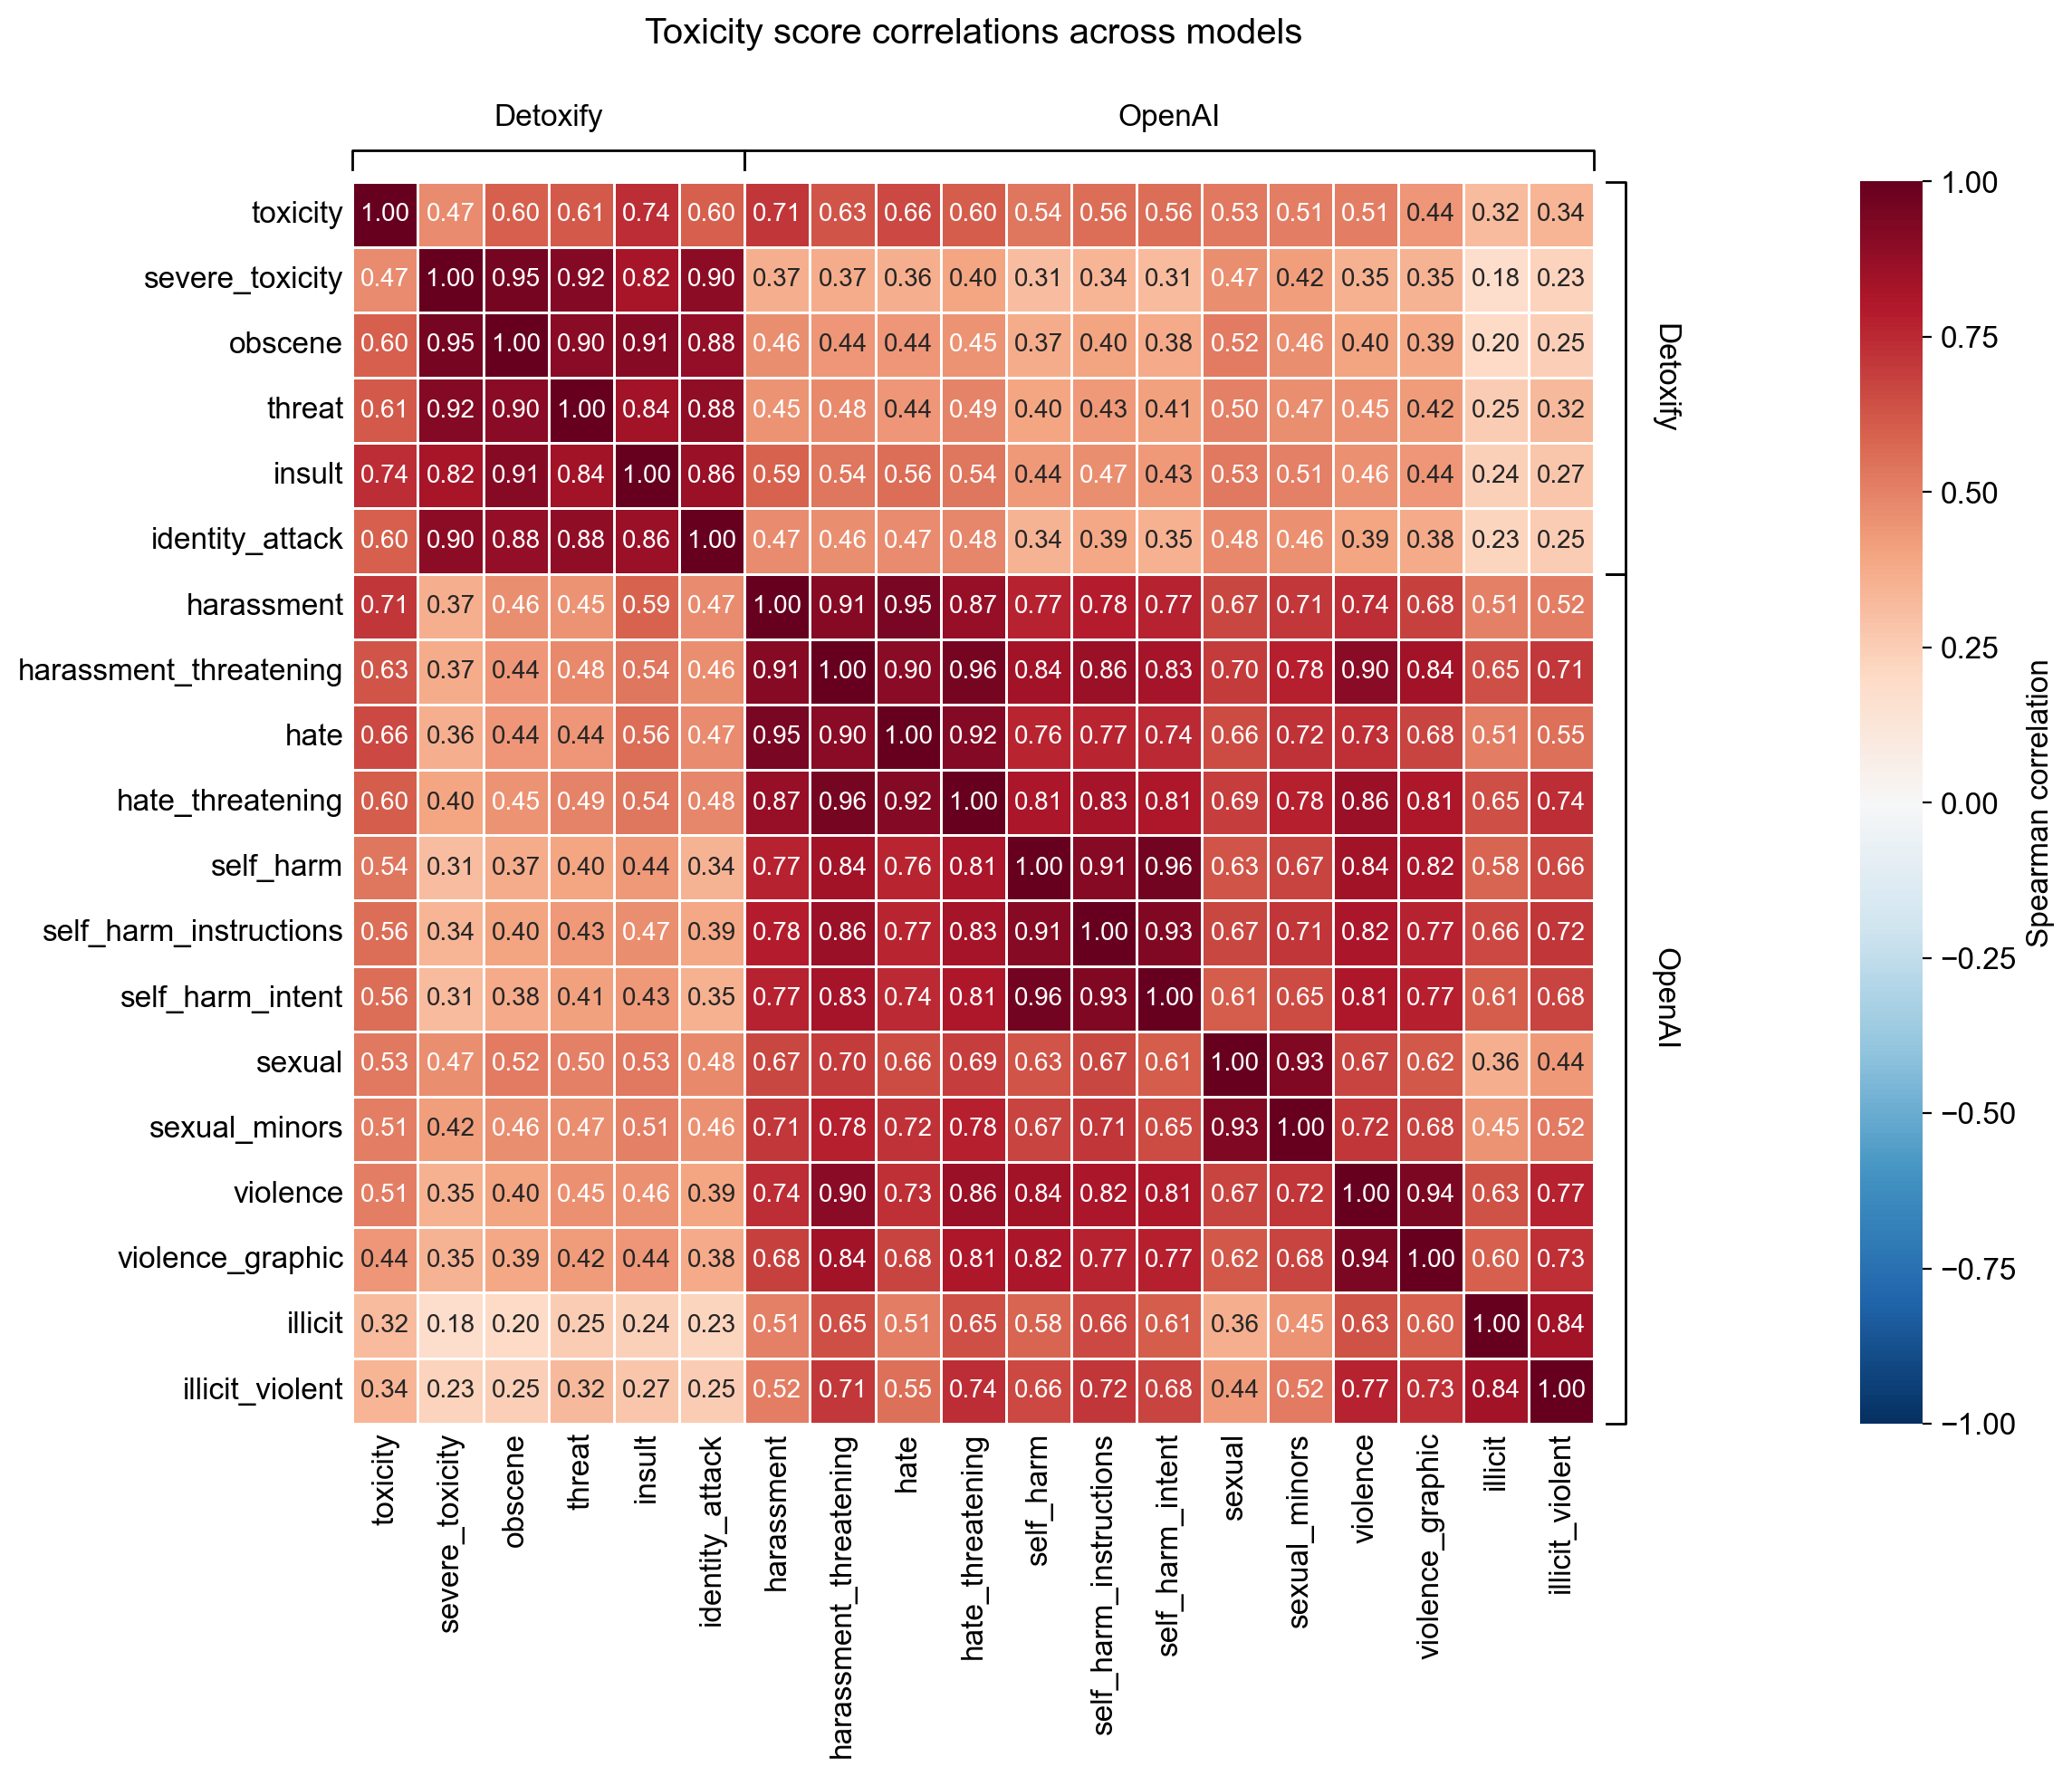

In [47]:
# Keep metrics from each model together
det_cols = [c for c in corr.columns if c.endswith("_detoxify")]
oai_cols = [c for c in corr.columns if c.endswith("_openai")]
order = det_cols + oai_cols
plot_corr = corr.loc[order, order]

labels = [c.removesuffix("_detoxify").removesuffix("_openai") for c in order]

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    plot_corr,
    xticklabels=labels,
    yticklabels=labels,
    cmap="RdBu_r",
    vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f",
    annot_kws={"fontsize": 10},
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Spearman correlation",
        "pad": 0.15,  # Space for brackets beside the matrix
        "shrink": 0.85,
    },
    ax=ax,
)

ax.tick_params(axis="both", length=0, labelsize=12)
plt.setp(ax.get_xticklabels(), rotation=90)
plt.setp(ax.get_yticklabels(), rotation=0)

# Draw brackets using coordinates relative to the axes
n = len(order)
groups = [
    ("Detoxify", 0, len(det_cols)),
    ("OpenAI", len(det_cols), n),
]

for name, start, end in groups:
    # Bracket above the columns
    x0, x1 = start / n, end / n
    ax.plot(
        [x0, x0, x1, x1],
        [1.01, 1.025, 1.025, 1.01],
        transform=ax.transAxes,
        color="black", lw=1, clip_on=False,
    )
    ax.text(
        (x0 + x1) / 2, 1.04, name,
        transform=ax.transAxes,
        ha="center", va="bottom", fontsize=12,
    )

    # Bracket beside the rows; the heatmap runs from top to bottom
    y0, y1 = 1 - start / n, 1 - end / n
    ax.plot(
        [1.01, 1.025, 1.025, 1.01],
        [y0, y0, y1, y1],
        transform=ax.transAxes,
        color="black", lw=1, clip_on=False,
    )
    ax.text(
        1.045, (y0 + y1) / 2, name,
        transform=ax.transAxes,
        ha="left", va="center", rotation=270, fontsize=12,
    )

ax.set_title(f"Toxicity score correlations across models", pad=55)
plt.tight_layout()
plt.savefig("../../../output/appendix/score_correlation_detoxify_openai.pdf", dpi=300, bbox_inches="tight")
plt.savefig("../../../output/appendix/score_correlation_detoxify_openai.png", dpi=300, bbox_inches="tight")